# 04 — Baseline estese: finestre, β a tratti, β lineare nella mobilità

Obiettivo: chiudere i punti aperti prima del GP.
1. **Scelta della finestra**: quanto varia la mobilità, e quanto si confonde con il tempo t.
2. **Le due baseline mancanti** del documento di progetto: β costante a tratti (un valore per periodo fra due provvedimenti) e β lineare nella mobilità, β(t) = β₀ · (1 + Σ cₖ xₖ(t)).
3. **Sensibilità su σ**: 1/3 (latenza con l'incubazione europea di Cheng et al.), 1/4 (latenza con Li et al.), 1/5,2 (incubazione di Li et al., valore attuale), 1/6 (incubazione globale di Cheng et al.), 1/6,4 (Elias et al.). Riferimenti nel notebook 02.

Impostazione identica alla sezione 6 del notebook 02, il riferimento per il GP: γ(t) e μ(t) dai dati, σ = 1/5.2, fitness normalizzata, training sui primi 2/3 della finestra, dati `clean`. Codice in `src/seird_gp/beta_models.py`, provvedimenti in `data/restrizioni_trento.csv`.

**Regola sul test**, uguale per tutte le baseline e per il GP: nessun dato futuro degli esiti (positivi, decessi, guariti); gli input esterni (mobilità osservata, date dei provvedimenti) si usano anche nel test. Nella baseline a tratti un periodo ha un suo β solo se ha almeno 7 giorni nel training; altrimenti (periodi che iniziano nel test o a ridosso della fine del training) resta al β del periodo precedente.

I fit (45, circa 2 ore e mezza con 2 core) si lanciano con `scripts/run_baselines.py`; qui si leggono i risultati da `results/04_baseline_all.pkl`.

In [1]:
import pickle
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from seird_gp.data import PROCESSED_DIR, RESULTS_DIR, load_mobility
from seird_gp.inputs import build_gp_inputs
from seird_gp.beta_models import load_restrictions

data = pd.read_csv(PROCESSED_DIR / "trento_clean.csv", index_col=0, parse_dates=True)
inputs = build_gp_inputs(load_mobility())
restr = load_restrictions()
WINDOWS = {"2020 (1/3–1/4)": ("2020-03-01", "2020-04-01"),
           "2021 (1/3–1/6)": ("2021-03-01", "2021-06-01"),
           "2022 (1/1–1/3)": ("2022-01-01", "2022-03-01"),
           "set20–gen21": ("2020-09-01", "2021-01-31"),
           "set20–feb21": ("2020-09-01", "2021-02-28")}
restr

,inizio,livello,provvedimento,fonte
0,2020-03-10,lockdown,DPCM 09/03/2020 (tutta Italia zona protetta),GU n. 62 del 09/03/2020
1,2020-03-12,lockdown,DPCM 11/03/2020 (chiusura attività commerciali...,GU n. 64 del 11/03/2020
2,2020-03-23,lockdown,DPCM 22/03/2020 (chiusura attività produttive ...,GU n. 76 del 22/03/2020
3,2020-10-26,misure nazionali,DPCM 24/10/2020 (bar e ristoranti chiusi alle ...,GU n. 265 del 25/10/2020
4,2020-11-06,gialla,DPCM 03/11/2020,DPC aree
5,2020-12-24,rossa/arancione,DL 18/12/2020 n. 172 (rossa nei festivi e pref...,DPC aree
6,2021-01-07,gialla,DL 05/01/2021 n. 1 (arancione 9-10/1); poi DPC...,DPC aree
7,2021-02-14,arancione,Ordinanza 12/02/2021,DPC aree
8,2021-03-15,rossa,Ordinanza 13/03/2021,DPC aree
9,2021-04-07,arancione,DL 01/04/2021 n. 44,DPC aree


## 1. Quanto varia la mobilità in ogni finestra

Per ogni finestra e per i due indici scelti nel notebook 03 (`lag0`):
- **escursione**: massimo − minimo, in punti percentuali. Se la mobilità non varia, il GP non può imparare niente su di essa;
- **R² con t**: quanto la mobilità è spiegata da una retta nel tempo. Se è alto, una formula in t imita quella in m(t) e il GP non può distinguerle (con t fra gli ingredienti);
- **|r| retail–work**: se è alto, i due indici sono intercambiabili (domanda D6 su quale conta).

In [2]:
rows = []
for name, (a, b) in WINDOWS.items():
    x = inputs.loc[a:b]
    t = np.arange(len(x))
    row = {"finestra": name, "giorni": len(x)}
    for col in ["retail_lag0", "work_lag0"]:
        short = col.split("_")[0]
        row[f"{short} escursione"] = round(100 * (x[col].max() - x[col].min()))
        row[f"{short} R² con t"] = round(np.corrcoef(t, x[col])[0, 1] ** 2, 2)
    row["|r| retail–work"] = round(abs(x["retail_lag0"].corr(x["work_lag0"])), 2)
    rows.append(row)
mob = pd.DataFrame(rows).set_index("finestra")
mob

,giorni,retail escursione,retail R² con t,work escursione,work R² con t,|r| retail–work
finestra,,,,,,
2020 (1/3–1/4),32,86,0.86,62,0.89,0.99
2021 (1/3–1/6),93,50,0.77,28,0.46,0.89
2022 (1/1–1/3),60,26,0.01,39,0.76,0.37
set20–gen21,153,80,0.75,50,0.43,0.81
set20–feb21,181,80,0.66,50,0.26,0.78


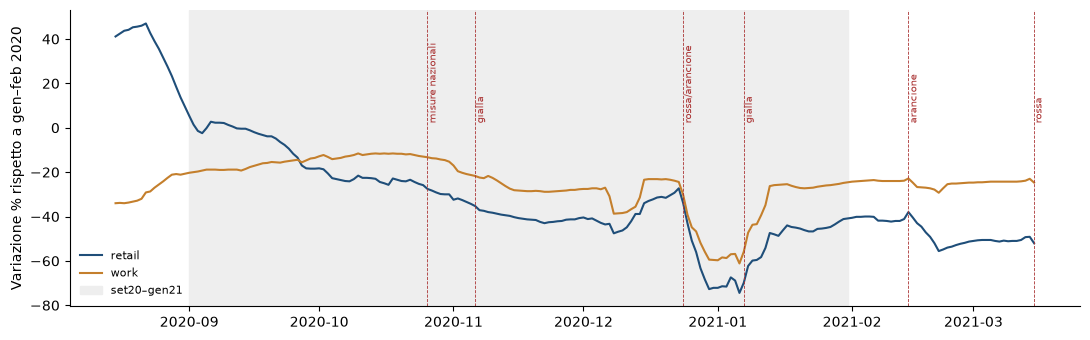

In [3]:
fig, ax = plt.subplots(figsize=(11, 3.5))
a, b = "2020-08-15", "2021-03-15"
for col, c in [("retail_lag0", "#1f4e79"), ("work_lag0", "#c47f2c")]:
    ax.plot(100 * inputs.loc[a:b, col], color=c, label=col.split("_")[0])
for _, r in restr[(restr.inizio >= a) & (restr.inizio <= b)].iterrows():
    ax.axvline(r.inizio, color="#a33", lw=0.6, ls="--")
    ax.text(r.inizio, 2, r.livello, rotation=90, fontsize=7, va="bottom", color="#a33")
ax.axvspan("2020-09-01", "2021-01-31", color="#eee", zorder=0, label="set20–gen21")
ax.set_ylabel("Variazione % rispetto a gen–feb 2020")
ax.legend(frameon=False, fontsize=8)
ax.spines[["top", "right"]].set_visible(False)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "04_mobilita_seconda_ondata.png", dpi=150)

**Lettura.**
- **2020**: un solo gradino in un mese, tutto si muove insieme (R² con t ≈ 0.9, retail e work quasi identici). Non serve a capire il ruolo della mobilità.
- **2022**: retail e work poco correlati (0.37): è la finestra per capire *quale* indice conta. Ma retail varia poco (26 punti) e work ha un forte trend nel tempo.
- **Seconda ondata**: la più lunga e quella in cui la mobilità si confonde meno con il tempo, soprattutto work fino a febbraio (R² 0.26). Non è però un su e giù ripetuto: è soprattutto una discesa fino al minimo del 6/1 (retail −74%, work −61%), in parte stagionale (ferie), poi un rimbalzo. In agosto retail è sopra la baseline per il turismo, che non fa parte di N: un motivo per iniziare a settembre.
- Fino a febbraio la mobilità si distingue meglio dal tempo, ma da febbraio si diffonde la variante Alpha, che il modello non vede. Scelta da prendere insieme al terminal set del GP (con o senza t).

## 2. Confronto fra le baseline

In [4]:
res = pickle.load(open(RESULTS_DIR / "04_baseline_all.pkl", "rb"))
REF = "σ = 1/5.2"
rows = []
for (w, m, s), r in res.items():
    if s != REF:
        continue
    rows.append({"finestra": w, "baseline": m, "n. parametri": r.extra["n_params"],
                 "fitness_norm train": r.rmsd.loc["train", "fitness_norm"],
                 "fitness_norm test": r.rmsd.loc["test", "fitness_norm"],
                 "RMSD D test": r.rmsd.loc["test", "D"], "RMSD I test": r.rmsd.loc["test", "I"],
                 "al bordo": ", ".join(r.extra["at_bound"])})
order = {"costante": 0, "a tratti": 1, "lineare retail": 2, "lineare work": 3, "lineare retail+work": 4}
win_order = {w: i for i, w in enumerate(WINDOWS)}
comp = (pd.DataFrame(rows).assign(o=lambda d: d.baseline.map(order), w=lambda d: d.finestra.map(win_order))
        .sort_values(["w", "o"]).drop(columns=["o", "w"]).set_index(["finestra", "baseline"]))
comp.to_csv(RESULTS_DIR / "04_baseline_estese.csv")
comp.round(3)

n. parametri  fitness_norm train  \
finestra       baseline                                                
2020 (1/3–1/4) costante                        2               0.268   
               a tratti                        4               0.225   
               lineare retail                  3               0.237   
               lineare work                    3               0.241   
               lineare retail+work             4               0.228   
2021 (1/3–1/6) costante                        2               0.121   
               a tratti                        4               0.112   
               lineare retail                  3               0.117   
               lineare work                    3               0.108   
               lineare retail+work             4               0.106   
2022 (1/1–1/3) costante                        2               0.229   
               a tratti                        2               0.229   
               lineare retail                  3               0.189   
               lineare work                    3               0.189   
               lineare retail+work             4               0.163   
set20–gen21    costante                        2               0.201   
               a tratti                        4               0.130   
               lineare retail                  3               0.162   
               lineare work                    3               0.137   
               lineare retail+work             4               0.119   
set20–feb21    costante                        2               0.220   
               a tratti                        5               0.131   
               lineare retail                  3               0.166   
               lineare work                    3               0.140   
               lineare retail+work             4               0.130   

                                    fitness_norm test  RMSD D test  \
finestra       baseline                                              
2020 (1/3–1/4) costante                         5.641       20.514   
               a tratti                         3.052       22.036   
               lineare retail                   2.852       31.509   
               lineare work                     3.616       37.314   
               lineare retail+work              4.719       17.173   
2021 (1/3–1/6) costante                         0.143        9.984   
               a tratti                         0.134        9.825   
               lineare retail                   0.362       17.816   
               lineare work                     0.292       14.895   
               lineare retail+work              0.147       10.185   
2022 (1/1–1/3) costante                         0.377        7.395   
               a tratti                         0.377        7.395   
               lineare retail                   0.498        6.218   
               lineare work                     0.330        8.771   
               lineare retail+work              0.343        9.583   
set20–gen21    costante                         1.923      223.645   
               a tratti                         0.307       28.605   
               lineare retail                   0.624       70.969   
               lineare work                     0.717       45.400   
               lineare retail+work              1.024       91.007   
set20–feb21    costante                         0.862      225.446   
               a tratti                         0.850       78.068   
               lineare retail                   0.885       40.330   
               lineare work                     1.033       40.327   
               lineare retail+work              1.009       49.292   

                                    RMSD I test     al bordo  
finestra       baseline                                       
2020 (1/3–1/4) costante                1950.070               
           

In [5]:
# parametri stimati della forma di β (coefficienti della mobilità e β dei periodi)
pars = {}
for (w, m, s), r in res.items():
    if s == REF and m != "costante":
        pars[(w, m)] = {k: v for k, v in r.params.items() if k.startswith(("beta_", "beta0", "c_"))}
pd.DataFrame(pars).T.reindex(columns=["beta_0", "beta_1", "beta_2", "beta_3", "beta0", "c_retail_lag0", "c_work_lag0"]).round(3)

beta_0  beta_1  beta_2  beta_3  beta0  \
2020 (1/3–1/4) a tratti              1.220   1.980   0.222     NaN    NaN   
               lineare retail          NaN     NaN     NaN     NaN  1.000   
               lineare work            NaN     NaN     NaN     NaN  0.895   
               lineare retail+work     NaN     NaN     NaN     NaN  1.271   
2021 (1/3–1/6) a tratti              0.065   0.045   0.054     NaN    NaN   
               lineare retail          NaN     NaN     NaN     NaN  0.118   
               lineare work            NaN     NaN     NaN     NaN  0.113   
               lineare retail+work     NaN     NaN     NaN     NaN  0.077   
2022 (1/1–1/3) a tratti              0.082     NaN     NaN     NaN    NaN   
               lineare retail          NaN     NaN     NaN     NaN  0.202   
               lineare work            NaN     NaN     NaN     NaN  0.049   
               lineare retail+work     NaN     NaN     NaN     NaN  0.083   
set20–gen21    a tratti              0.109   0.151   0.076     NaN    NaN   
               lineare retail          NaN     NaN     NaN     NaN  0.151   
               lineare work            NaN     NaN     NaN     NaN  0.170   
               lineare retail+work     NaN     NaN     NaN     NaN  0.141   
set20–feb21    a tratti              0.109   0.150   0.079   0.078    NaN   
               lineare retail          NaN     NaN     NaN     NaN  0.154   
               lineare work            NaN     NaN     NaN     NaN  0.160   
               lineare retail+work     NaN     NaN     NaN     NaN  0.127   

                                    c_retail_lag0  c_work_lag0  
2020 (1/3–1/4) a tratti                       NaN          NaN  
               lineare retail               0.982          NaN  
               lineare work                   NaN        1.433  
               lineare retail+work          3.015       -3.000  
2021 (1/3–1/6) a tratti                       NaN          NaN  
               lineare retail               1.020          NaN  
               lineare work                   NaN        1.822  
               lineare retail+work         -1.257        3.481  
2022 (1/1–1/3) a tratti                       NaN          NaN  
               lineare retail               2.923          NaN  
               lineare work                   NaN       -3.000  
               lineare retail+work          3.352       -2.999  
set20–gen21    a tratti                       NaN          NaN  
               lineare retail               1.030          NaN  
               lineare work                   NaN        1.927  
               lineare retail+work         -2.277        5.000  
set20–feb21    a tratti                       NaN          NaN  
               lineare retail               1.100          NaN  
               lineare work                   NaN        1.712  
               lineare retail+work         -1.913        3.980

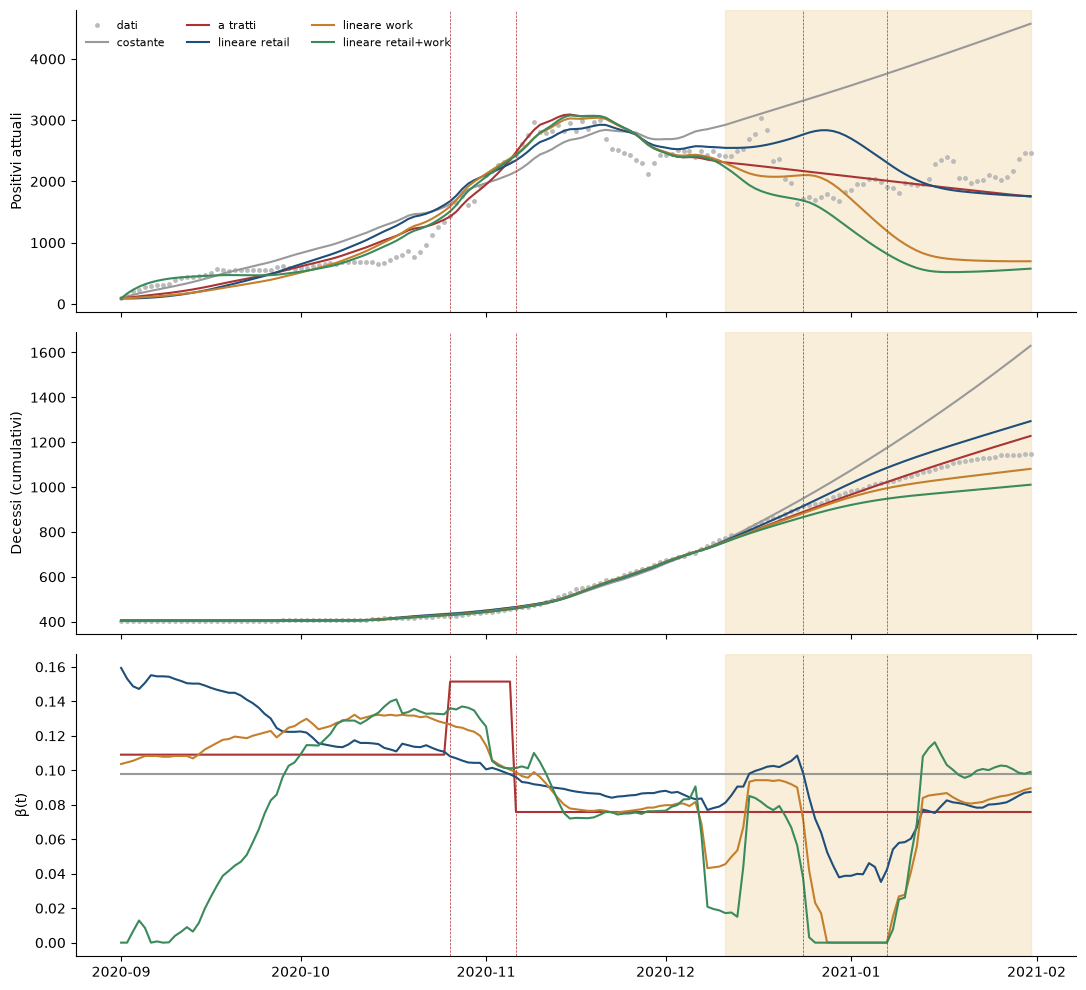

In [6]:
W = "set20–gen21"
a, b = WINDOWS[W]
obs = data.loc[a:b]
colors = {"costante": "#999", "a tratti": "#a33", "lineare retail": "#1f4e79",
          "lineare work": "#c47f2c", "lineare retail+work": "#3a8a5c"}
fig, ax = plt.subplots(3, 1, figsize=(11, 10), sharex=True)
ax[0].plot(obs.index, obs.totale_positivi, "o", ms=2.5, color="#bbb", label="dati")
ax[1].plot(obs.index, obs.deceduti, "o", ms=2.5, color="#bbb", label="dati")
for m, c in colors.items():
    r = res[(W, m, REF)]
    ax[0].plot(r.simulation["I"], color=c, label=m)
    ax[1].plot(r.simulation["D"], color=c)
    ax[2].plot(r.extra["beta"], color=c, label=m)
for x in ax:
    x.axvspan(res[(W, "costante", REF)].train_end, obs.index[-1], color="#f4e3c1", alpha=0.6)
    for d in restr.inizio[(restr.inizio > a) & (restr.inizio <= b)]:
        x.axvline(d, color="#a33", lw=0.5, ls="--")
    x.spines[["top", "right"]].set_visible(False)
ax[0].set_ylabel("Positivi attuali"); ax[1].set_ylabel("Decessi (cumulativi)"); ax[2].set_ylabel("β(t)")
ax[0].legend(frameon=False, fontsize=8, ncol=3)
fig.tight_layout(); fig.savefig(RESULTS_DIR / "04_baseline_seconda_ondata.png", dpi=150)

**Lettura** (fitness normalizzata sul test, più bassa è meglio).

- **Far variare β aiuta quasi sempre**, ma quale forma vince dipende dalla finestra:
  - 2020: lineare retail (2.85) e a tratti (3.05) dimezzano l'errore della costante (5.64);
  - 2021: a tratti (0.134) di poco meglio della costante (0.143) e di retail+work (0.147); le lineari con un solo indice peggiorano;
  - 2022: nessun cambio di colore, quindi a tratti = costante (0.377); lineare work (0.330) di poco meglio;
  - **set 2020 – gen 2021: a tratti 0.307 contro 1.92 della costante e 0.62–1.02 delle lineari.** Le date dei provvedimenti spiegano i contagi molto meglio della mobilità da sola. Primo indizio per D6: la mobilità non cattura tutto ciò che le restrizioni cambiano (mascherine, scuole, orari dei locali), come previsto nel documento di progetto;
  - set 2020 – feb 2021: tutte vicine (0.83–1.03).
- **Baseline a tratti, regola dei 7 giorni.** Nel 2021 l'ultimo periodo del training (gialla dal 26/4) aveva 5 giorni: con un β suo l'errore di test era 0.938, ora è 0.134.
- **Limite della baseline a tratti (da risolvere):** nel test resta al β dell'ultimo periodo stimato. Fino a febbraio il training finisce il 30/12, quindi il β del periodo natalizio (rossa/arancione) viene applicato a gennaio–febbraio, che erano in zona gialla. Per questo lì perde il vantaggio. Alternativa più corretta: **un β per livello di restrizione**, riusato nel test quando il livello è già comparso nel training.
- **Due indici correlati vanno in overfitting.** Con retail + work il coefficiente di work finisce al bordo (c = −3) in 2020, 2022 e set–gen, compensato da un coefficiente alto di retail: meglio nel training, peggio nel test. Per il GP: pochi input e un obiettivo sulla lunghezza della formula sono necessari.
- **Coefficienti negativi sospetti.** Nel 2022 work ha c = −3 (più lavoro → meno contagi): quasi certamente assorbe il trend di Omicron (R² di work con t = 0.76). È il rischio di confondere mobilità e tempo.
- **Nel grafico (set 2020 – gen 2021) due segnali da non ignorare:**
  - nella baseline a tratti β **sale** dal 26/10 al 5/11 (da 0.11 a 0.15), proprio quando le misure si stringono, e scende solo con le zone dal 6/11. Non è un effetto delle misure: è il picco di contagi di fine ottobre che si vede nei positivi con qualche giorno di ritardo (notifica), assegnato al periodo sbagliato. È lo stesso ritardo di notifica che il notebook 03 prevede di diagnosticare con i lag della mobilità; con la baseline a tratti va tenuto presente nell'interpretare D4;
  - la baseline retail + work porta β a **0 per settimane** (inizio settembre, intorno a Natale): è il taglio a β ≥ 0 attivato dal coefficiente di work al bordo. Una formula del GP con questo comportamento andrebbe scartata anche se fitta bene.
- **Termine di confronto per il GP**: in ogni finestra la baseline migliore di questa tabella, non solo la costante. Il GP ha senso solo se batte anche la lineare (domanda D6) e la a tratti (D3).

## 3. Sensibilità su σ (β costante)

In [7]:
SIG = {"σ = 1/3 (latenza, Europa)": 1 / 3, "σ = 1/4 (latenza)": 1 / 4, "σ = 1/5.2": 1 / 5.2,
       "σ = 1/6 (incubazione globale)": 1 / 6, "σ = 1/6.4 (meta-analisi)": 1 / 6.4}
rows = []
for (w, m, s), r in res.items():
    if m == "costante":
        rows.append({"finestra": w, "σ": s, "beta": r.params["beta"], "E0": r.params["E0"],
                     "fitness_norm train": r.rmsd.loc["train", "fitness_norm"],
                     "fitness_norm test": r.rmsd.loc["test", "fitness_norm"]})
sens = (pd.DataFrame(rows).assign(w=lambda d: d.finestra.map(win_order), d=lambda d: d.σ.map(lambda x: 1 / SIG[x]))
        .sort_values(["w", "d"]).drop(columns=["w", "d"]).set_index(["finestra", "σ"]))
sens.round(3)

beta         E0  \
finestra       σ                                                 
2020 (1/3–1/4) σ = 1/3 (latenza, Europa)      0.291     48.002   
               σ = 1/4 (latenza)              0.324     56.876   
               σ = 1/5.2                      0.363     67.673   
               σ = 1/6 (incubazione globale)  0.389     74.692   
               σ = 1/6.4 (meta-analisi)       0.402     78.394   
2021 (1/3–1/6) σ = 1/3 (latenza, Europa)      0.054   1557.311   
               σ = 1/4 (latenza)              0.052   1888.486   
               σ = 1/5.2                      0.050   2289.437   
               σ = 1/6 (incubazione globale)  0.049   2549.203   
               σ = 1/6.4 (meta-analisi)       0.048   2686.631   
2022 (1/1–1/3) σ = 1/3 (latenza, Europa)      0.084  10139.192   
               σ = 1/4 (latenza)              0.083  12175.495   
               σ = 1/5.2                      0.082  14597.370   
               σ = 1/6 (incubazione globale)  0.081  16179.843   
               σ = 1/6.4 (meta-analisi)       0.080  16910.887   
set20–gen21    σ = 1/3 (latenza, Europa)      0.094    118.764   
               σ = 1/4 (latenza)              0.096    153.056   
               σ = 1/5.2                      0.098    193.842   
               σ = 1/6 (incubazione globale)  0.099    221.403   
               σ = 1/6.4 (meta-analisi)       0.100    235.821   
set20–feb21    σ = 1/3 (latenza, Europa)      0.090    167.219   
               σ = 1/4 (latenza)              0.091    213.903   
               σ = 1/5.2                      0.092    270.621   
               σ = 1/6 (incubazione globale)  0.093    308.768   
               σ = 1/6.4 (meta-analisi)       0.094    328.432   

                                              fitness_norm train  \
finestra       σ                                                   
2020 (1/3–1/4) σ = 1/3 (latenza, Europa)                   0.268   
               σ = 1/4 (latenza)                           0.268   
               σ = 1/5.2                                   0.268   
               σ = 1/6 (incubazione globale)               0.267   
               σ = 1/6.4 (meta-analisi)                    0.267   
2021 (1/3–1/6) σ = 1/3 (latenza, Europa)                   0.125   
               σ = 1/4 (latenza)                           0.123   
               σ = 1/5.2                                   0.121   
               σ = 1/6 (incubazione globale)               0.120   
               σ = 1/6.4 (meta-analisi)                    0.120   
2022 (1/1–1/3) σ = 1/3 (latenza, Europa)                   0.239   
               σ = 1/4 (latenza)                           0.234   
               σ = 1/5.2                                   0.229   
               σ = 1/6 (incubazione globale)               0.227   
               σ = 1/6.4 (meta-analisi)                    0.226   
set20–gen21    σ = 1/3 (latenza, Europa)                   0.192   
               σ = 1/4 (latenza)                           0.196   
               σ = 1/5.2                                   0.201   
               σ = 1/6 (incubazione globale)               0.204   
               σ = 1/6.4 (meta-analisi)                    0.205   
set20–feb21    σ = 1/3 (latenza, Europa)                   0.204   
               σ = 1/4 (latenza)                           0.211   
               σ = 1/5.2                                   0.220   
               σ = 1/6 (incubazione globale)               0.225   
               σ = 1/6.4 (meta-analisi)                    0.227   

                                              fitness_norm test  
finestra       σ                                                 
2020 (1/3–1/4) σ = 1/3 (latenza, Europa)                  5.723  
               σ = 1/4 (latenza)                          5.693  
               σ = 1/5.2                                  5.641  
               σ = 1/6 (incubazione globale)              5.628  
               σ = 1/6.4 (meta-

**Lettura.**
- **Nelle finestre del paper σ conta poco**: l'errore di test cambia di meno del 7% fra σ = 1/3 e σ = 1/6.4 (2020: 5.61–5.72; 2021: 0.142–0.145; 2022: 0.36–0.39).
- **Nella seconda ondata conta di più**: fino a gennaio l'errore va da 1.65 (σ = 1/3) a 2.05 (σ = 1/6.4), circa il 25%; fino a febbraio da 0.83 a 0.90. Su cinque mesi gli scarti sulla velocità della catena dei contagi si accumulano.
- **σ più veloci fittano meglio nella seconda ondata**, coerente con l'incubazione europea più breve (4.6 gg, Cheng et al.) e con l'interpretazione di σ come latenza.
- **β si sposta in modo sistematico**: con σ più lento serve un β più alto (2020: 0.29 → 0.40), mentre E₀ cresce. I valori di β e R_t vanno sempre riportati insieme al σ usato.
- **La classifica fra le baseline non cambia**: nella seconda ondata la β costante resta fra 1.65 e 2.05 con qualunque σ, lontana dalla a tratti (0.31). La sensibilità qui è fatta solo sulla β costante; per il GP andrà ripetuta almeno con σ = 1/3 e 1/5.2.

## Conclusioni e decisioni aperte

1. **Finestra e terminal set** (insieme): seconda ondata fino a gennaio o febbraio, con o senza t fra gli ingredienti.
2. **Baseline a tratti per livello di restrizione**, per non trascinare nel test il β di un periodo atipico (Natale).
3. **σ di riferimento**: 1/5.2 resta difendibile come incubazione; come latenza, 1/3–1/4 è più coerente e fitta meglio la seconda ondata. Proposta: riferimento 1/4, sensibilità 1/3 e 1/5.2.
4. **Da verificare**: gli estremi di Gazzetta Ufficiale dei DPCM in `data/restrizioni_trento.csv` (le zone colorate vengono invece dai dati ufficiali DPC).